# Пактическая работа №6

## 1. Визуализация датасетов

Создадим по 200 точек в форме двух лун и двух окружностей.

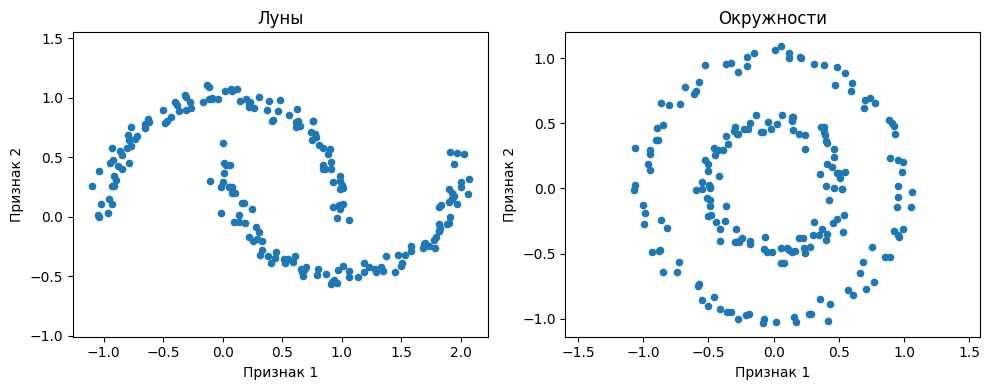

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_circles
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from scipy.cluster.hierarchy import linkage, dendrogram

X_moons, _ = make_moons(n_samples=200, noise=0.05, random_state=42)
X_circles, _ = make_circles(n_samples=200, noise=0.05, factor=0.5, random_state=42)

datasets = {"Луны": X_moons, "Окружности": X_circles}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, X) in zip(axes, datasets.items()):
    ax.scatter(X[:, 0], X[:, 1], s=20)
    ax.set_title(name)
    ax.set_xlabel("Признак 1")
    ax.set_ylabel("Признак 2")
    ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout()
plt.show()

## 2. KMeans (n_clusters=2)

Метод k-средних относит каждую точку к ближайшему центру кластера. Центр пересчитывается как среднее всех точек кластера.

Расстояние между точками вычисляется по формуле:

$$d(x,y)=\sqrt{\sum_{i=1}^{n}(x_i-y_i)^2}$$

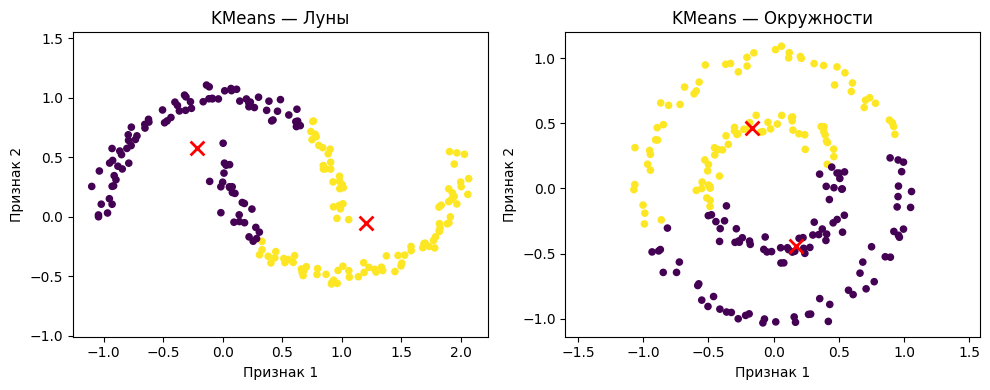

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, X) in zip(axes, datasets.items()):
    model = KMeans(n_clusters=2, random_state=42, n_init=10)
    labels = model.fit_predict(X)
    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=20)
    ax.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1],
               c="red", marker="x", s=100, linewidths=2)
    ax.set_title(f"KMeans — {name}")
    ax.set_xlabel("Признак 1")
    ax.set_ylabel("Признак 2")
    ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout()
plt.show()

**Объяснение неудачи:** KMeans разделяет точки по расстоянию до центров. Поэтому на лунах смешиваются части разных дуг, а на окружностях алгоритм не отделяет внутреннее кольцо от внешнего.

## 3. Агломеративная кластеризация

**Отличие от KMeans**: KMeans распределяет точки относительно центров кластеров, а агломеративная кластеризация постепенно объединяет точки и группы по их близости.

Алгоритм сначала считает каждую точку отдельным кластером, а затем последовательно объединяет ближайшие кластеры.

Проверим три типа связи: ward, average, complete, задав два кластера.

**Complete**: «Выберу группы, у которых даже самые далёкие точки не слишком далеко друг от друга».

**Average:** «Выберу группы, у которых точки в среднем ближе друг к другу».

**Ward:** «Выберу группы, объединение которых меньше всего увеличит разброс».

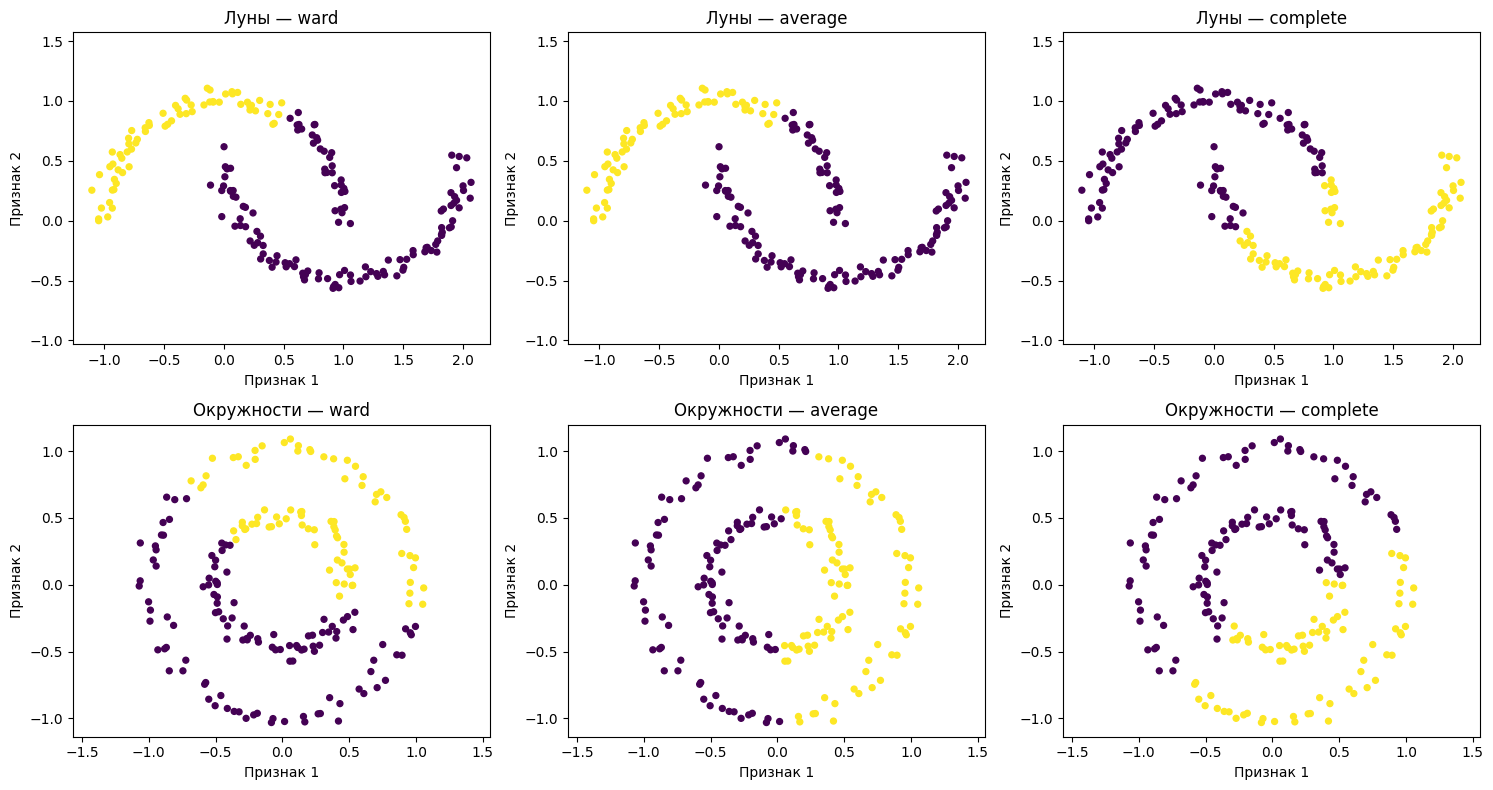

In [ ]:
linkage_types = ["ward", "average", "complete"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row, (name, X) in enumerate(datasets.items()):
    for col, method in enumerate(linkage_types):
        labels = AgglomerativeClustering(n_clusters=2, linkage=method).fit_predict(X)
        ax = axes[row, col]
        ax.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=18)
        ax.set_title(f"{name} — {method}")
        ax.set_xlabel("Признак 1")
        ax.set_ylabel("Признак 2")
        ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout()
plt.show()

**Дендрограмма** — это древовидная диаграмма, которая показывает, в каком порядке алгоритм объединял точки в кластеры.

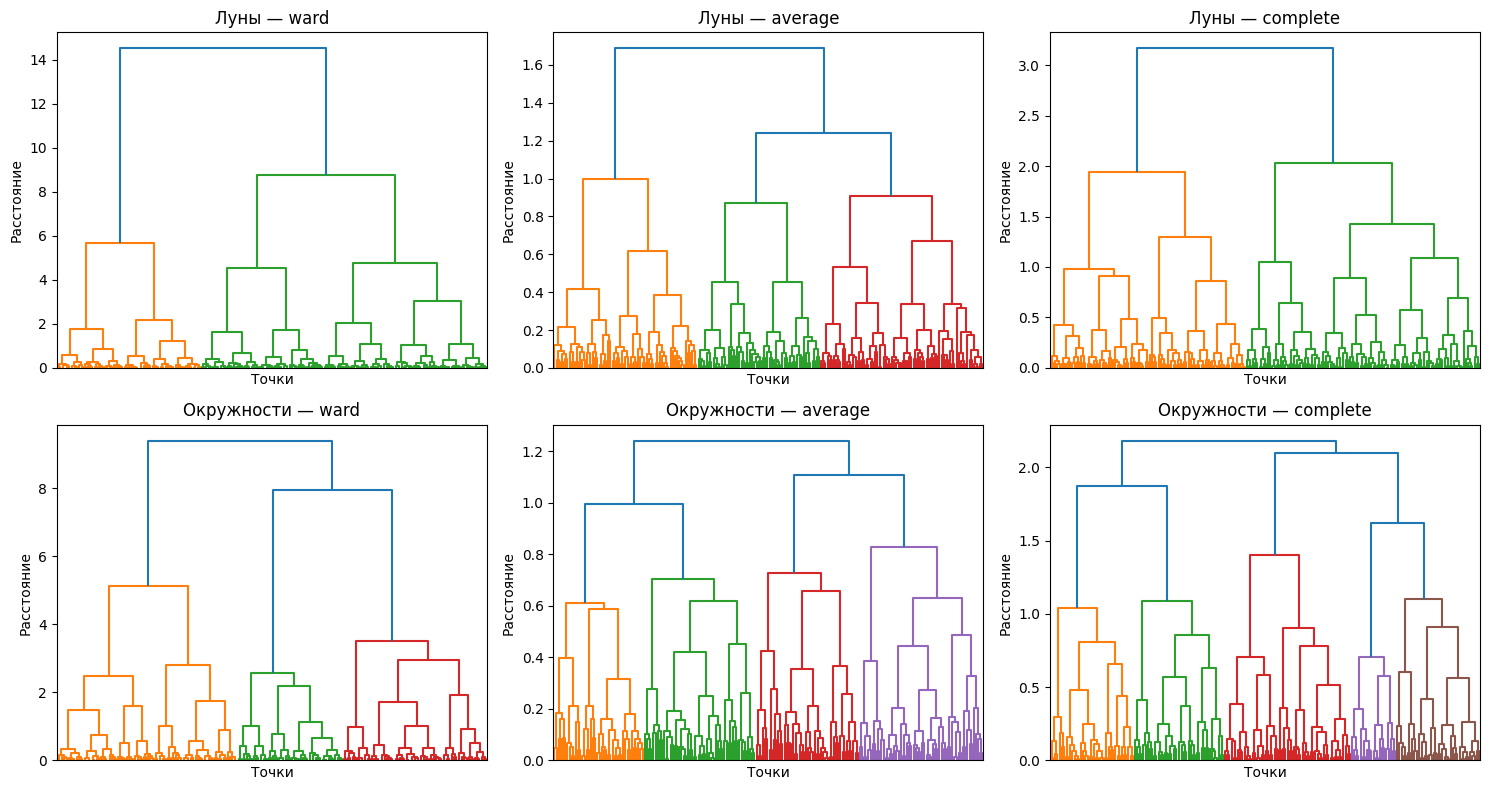

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row, (name, X) in enumerate(datasets.items()):
    for col, method in enumerate(linkage_types):
        Z = linkage(X, method=method)
        ax = axes[row, col]
        dendrogram(Z, ax=ax, no_labels=True)
        ax.set_title(f"{name} — {method}")
        ax.set_xlabel("Точки")
        ax.set_ylabel("Расстояние")
plt.tight_layout()
plt.show()

**Результат:** при всех трёх вариантах связи естественные формы лун и окружностей выделяются с ошибками. Дендрограммы показывают, на каких расстояниях объединяются группы.

## 4. DBSCAN

**DBSCAN** — это алгоритм кластеризации, который объединяет точки по плотности их расположения.

DBSCAN объединяет точки, имеющие достаточно соседей в радиусе eps. Параметр min_samples задаёт минимальное число точек в такой окрестности. Метка -1 обозначает шум.



**KMeans** — группирует точки вокруг центров.

**AgglomerativeClustering** — постепенно объединяет ближайшие группы.

**DBSCAN** — ищет области, где точки расположены достаточно плотно, и объединяет их в кластеры.

In [ ]:
eps_values = [0.12, 0.16, 0.18, 0.20, 0.25]
min_samples_values = [3, 5, 7]

for name, X in datasets.items():
    print(f"\n{name}:")
    print("eps | min_samples | кластеров | шумовых точек")
    for min_samples in min_samples_values:
        for eps in eps_values:
            labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
            clusters_count = len(set(labels) - {-1})
            noise_count = (labels == -1).sum()
            print(f"{eps:.2f} | {min_samples:^11} | {clusters_count:^9} | {noise_count}")


Луны:
eps | min_samples | кластеров | шумовых точек
0.12 |      3      |     6     | 3
0.16 |      3      |     3     | 1
0.18 |      3      |     2     | 0
0.20 |      3      |     2     | 0
0.25 |      3      |     2     | 0
0.12 |      5      |     5     | 7
0.16 |      5      |     2     | 5
0.18 |      5      |     2     | 0
0.20 |      5      |     2     | 0
0.25 |      5      |     2     | 0
0.12 |      7      |    14     | 35
0.16 |      7      |     2     | 6
0.18 |      7      |     2     | 4
0.20 |      7      |     2     | 0
0.25 |      7      |     2     | 0

Окружности:
eps | min_samples | кластеров | шумовых точек
0.12 |      3      |    18     | 14
0.16 |      3      |    11     | 0
0.18 |      3      |     4     | 0
0.20 |      3      |     2     | 0
0.25 |      3      |     1     | 0
0.12 |      5      |     5     | 79
0.16 |      5      |     9     | 26
0.18 |      5      |    10     | 0
0.20 |      5      |     2     | 0
0.25 |      5      |     1     | 0
0.12 |   

При маленьких значениях eps точки могут разделяться на много кластеров или становиться шумом. При слишком больших — разные группы могут соединиться.

Выбираем для дальнейших графиков: для лун eps=0.18, для окружностей eps=0.20, в обоих случаях min_samples=5. Эти значения дают по два кластера без шумовых точек. Это не единственные подходящие варианты.

Луны: кластеров — 2, шумовых точек — 0
Окружности: кластеров — 2, шумовых точек — 0


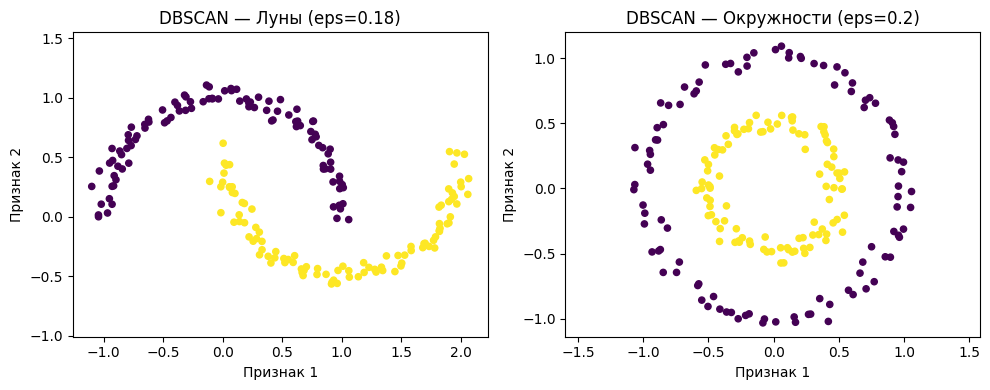

In [ ]:
parameters = {"Луны": 0.18, "Окружности": 0.20}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, X) in zip(axes, datasets.items()):
    eps = parameters[name]
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    clusters_count = len(set(labels) - {-1})
    noise_count = (labels == -1).sum()

    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=20)
    ax.set_title(f"DBSCAN — {name} (eps={eps})")
    ax.set_xlabel("Признак 1")
    ax.set_ylabel("Признак 2")
    ax.set_aspect("equal", adjustable="datalim")
    print(f"{name}: кластеров — {clusters_count}, шумовых точек — {noise_count}")
plt.tight_layout()
plt.show()

**Результат:** DBSCAN правильно выделил две луны и два кольца. В обоих наборах данных шумовых точек нет (0).

## Дополнительное задание. DBSCAN на Iris

Датасет Iris содержит 150 цветков трёх видов и четыре числовых признака. Применим DBSCAN ко всем четырём признакам. Перед кластеризацией стандартизируем признаки, чтобы различия в их масштабе не влияли на расстояния.

Количество кластеров: 2
Шумовых точек: 4


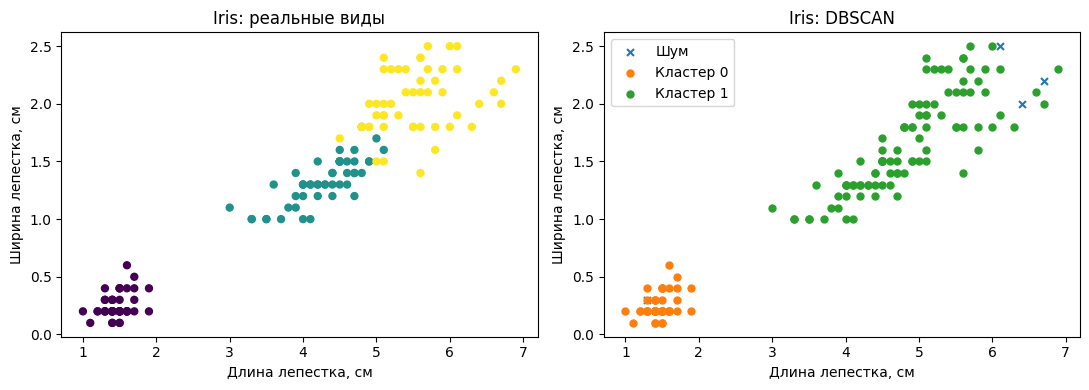

In [ ]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)

labels_iris = DBSCAN(eps=0.8, min_samples=5).fit_predict(X_iris)

clusters_count = len(set(labels_iris) - {-1})
noise_count = (labels_iris == -1).sum()
print(f"Количество кластеров: {clusters_count}")
print(f"Шумовых точек: {noise_count}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(iris.data[:, 2], iris.data[:, 3], c=iris.target, cmap="viridis", s=25)
axes[0].set_title("Iris: реальные виды")

for label in sorted(set(labels_iris)):
    mask = labels_iris == label
    axes[1].scatter(iris.data[mask, 2], iris.data[mask, 3],
                    s=25, marker="x" if label == -1 else "o",
                    label="Шум" if label == -1 else f"Кластер {label}")
axes[1].set_title("Iris: DBSCAN")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("Длина лепестка, см")
    ax.set_ylabel("Ширина лепестка, см")
plt.tight_layout()
plt.show()

**Результат для Iris:** DBSCAN выделил 2 кластера и 4 шумовые точки. Один кластер содержит почти все цветки вида setosa (49 из 50). В другой попали все 50 цветков versicolor и 47 цветков virginica. Остальные 4 цветка отмечены как шум. Таким образом, DBSCAN хорошо отделил setosa, но не разделил два других вида на самостоятельные кластеры.